# 09 · Atribución multitoque contra la verdad

**Sesión 9 · Analítica digital y atribución** (ruta Paid Media, semana 6: atribución por Markov frente a último clic; catálogo: atribución multitoque, Markov y Shapley).

500 mil recorridos sintéticos por 7 canales, con la atribución Shapley **verdadera** de cada recorrido que convirtió (6%). Se comparan 8 métodos por la participación que le dan a cada canal y su error contra la verdad. `python -m growth_lab.atribucion` (≈ 30 s); todo se lee de `data/processed/atr_*`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from growth_lab import db

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
P = db.PROCESSED
part = pd.read_parquet(P / "atr_participacion.parquet").set_index("canal")
err = pd.read_parquet(P / "atr_error.parquet")
cpc = pd.read_parquet(P / "atr_costo_por_conversion.parquet").set_index("canal")

## 1. ¿Cuánto se equivoca cada método? (error absoluto medio en puntos porcentuales)

In [2]:
err.round(3)

,metodo,mae_pp,mae_p05,mae_p95,canal_mas_sobreatribuido,sobre_pp,canal_mas_subatribuido,sub_pp
0,shapley_modelo,0.297,0.291,0.304,display,0.644,direct,-0.425
1,ultimo_clic,1.990,1.900,2.076,display,5.378,paid_search,-3.758
2,decaimiento_temporal,2.096,2.073,2.117,display,5.501,paid_search,-4.190
3,shapley_datos,2.177,NaN,NaN,display,5.590,paid_search,-5.178
4,en_u,2.219,2.173,2.266,display,5.748,paid_search,-4.580
5,lineal,2.235,2.202,2.267,display,5.775,paid_search,-4.621
6,markov,2.338,2.293,2.384,display,5.933,paid_search,-6.310
7,primer_clic,2.426,2.298,2.531,display,6.106,paid_search,-5.324


## 2. Participación de cada canal: los métodos contra la verdad

Todas las reglas y Markov reparten según **quién aparece** en el recorrido; display aparece mucho pero causa poco. El Shapley sobre un modelo de conversión mide **cuánto sube la probabilidad** cada canal.

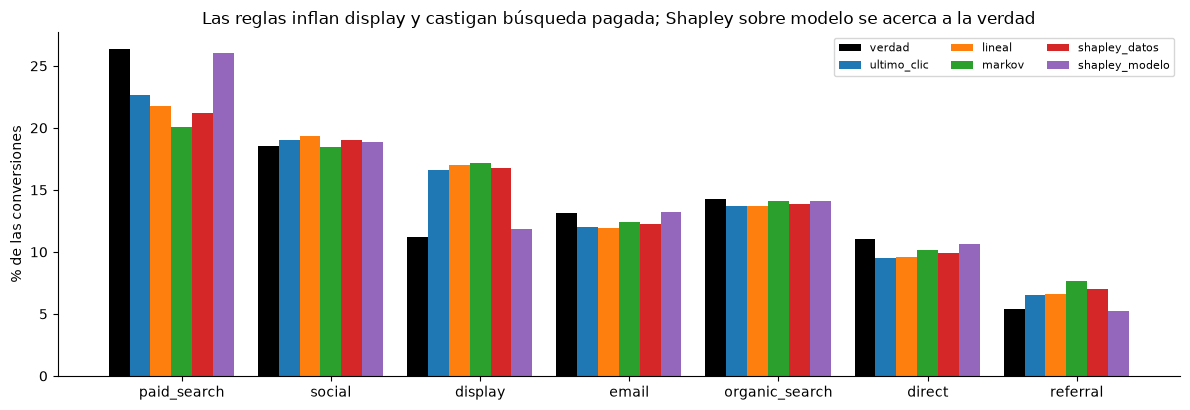

,ultimo_clic,primer_clic,lineal,decaimiento_temporal,en_u,markov,shapley_datos,shapley_modelo
canal,,,,,,,,
paid_search,-3.76,-5.32,-4.62,-4.19,-4.58,-6.31,-5.18,-0.32
social,0.49,0.93,0.80,0.68,0.76,-0.14,0.43,0.28
display,5.38,6.11,5.77,5.50,5.75,5.93,5.59,0.64
email,-1.14,-1.05,-1.18,-1.16,-1.14,-0.75,-0.91,0.12
organic_search,-0.54,-0.66,-0.54,-0.50,-0.56,-0.11,-0.36,-0.14
direct,-1.52,-1.45,-1.48,-1.49,-1.49,-0.88,-1.17,-0.42
referral,1.10,1.46,1.24,1.16,1.26,2.25,1.60,-0.15


In [3]:
metodos = ["ultimo_clic", "lineal", "markov", "shapley_datos", "shapley_modelo"]
x = np.arange(len(part)); w = 0.14
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(x - 3 * w, part.verdad * 100, w, label="verdad", color="black")
for k, m in enumerate(metodos):
    ax.bar(x + (k - 2) * w, part[m] * 100, w, label=m)
ax.set_xticks(x, part.index); ax.set_ylabel("% de las conversiones")
ax.set_title("Las reglas inflan display y castigan búsqueda pagada; Shapley sobre modelo se acerca a la verdad")
ax.legend(ncol=3, fontsize=8); fig.tight_layout(); fig.savefig("../docs/img/atr_participacion.png", dpi=150); plt.show()
((part.drop(columns="verdad").sub(part.verdad, axis=0)) * 100).round(2)

## 3. Lo que cambia para el presupuesto: costo por conversión atribuida

Solo canales con costo por toque (orgánica y directo son costo fijo, decisión 004).

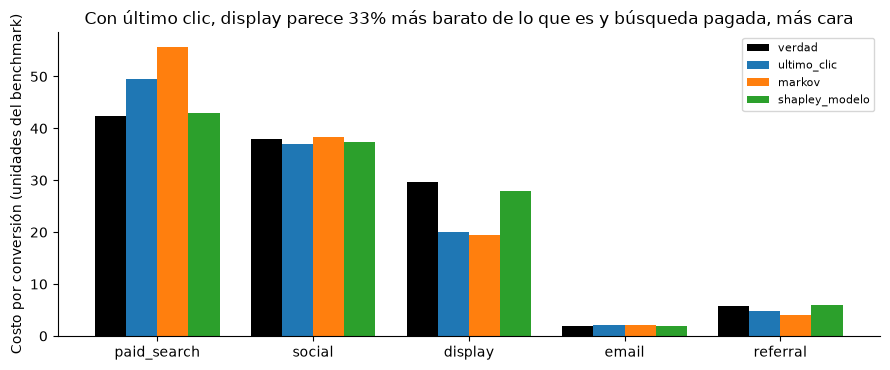

,verdad (% vs verdad),ultimo_clic (% vs verdad),markov (% vs verdad),shapley_modelo (% vs verdad)
canal,,,,
paid_search,0.0,16.6,31.4,1.2
social,0.0,-2.5,0.7,-1.5
display,0.0,-32.4,-34.6,-5.4
email,0.0,9.5,6.1,-0.9
referral,0.0,-17.0,-29.4,2.9


In [4]:
c = cpc[["verdad", "ultimo_clic", "markov", "shapley_modelo"]]
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(c)); w = 0.2
for k, m in enumerate(c.columns):
    ax.bar(x + (k - 1.5) * w, c[m], w, label=m, color="black" if m == "verdad" else None)
ax.set_xticks(x, c.index); ax.set_ylabel("Costo por conversión (unidades del benchmark)")
ax.set_title("Con último clic, display parece 33% más barato de lo que es y búsqueda pagada, más cara")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig("../docs/img/atr_costo.png", dpi=150); plt.show()
(c.div(c.verdad, axis=0) - 1).mul(100).round(1).rename(columns=lambda m: f"{m} (% vs verdad)")

## Mis conclusiones (Neider)

1. **Las reglas simples se equivocan todas en la misma dirección:** premian a display (+5 a +6 puntos) y castigan a búsqueda pagada (−4 a −6). Reparten según quién aparece en el recorrido, no según quién causa la venta.
2. **Markov no es la solución que parece:** fue de los peores (2,3 puntos de error) aunque se venda como "basado en datos".
3. **Shapley sobre un modelo de conversión se acerca a la verdad siete veces más** (0,30 puntos de error). Es la lógica de la atribución basada en datos de GA4. Ojo: aquí el modelo tiene la misma forma que el proceso que generó los datos, así que con datos reales hay que validarlo con experimentos.
4. **Para el presupuesto importa mucho:** con último clic, display parece un 32% más barato por conversión de lo que es y búsqueda pagada un 17% más cara. Eso confirma mi decisión de la sesión 4: mover presupuesto de display hacia búsqueda.
5. **E-mail es el canal más barato por conversión,** pero lo escalo con una prueba controlada porque su rendimiento cae si se manda de más. Orgánica y directo siguen como costo fijo.